# CSLC Sentinel-1 assessment (ETAD)

In [ ]:
"""
File Name: cslc_assessment_sentinel1.ipynb

Author:
    Francesco Vecchioli
    B-Open Solutions srl

Date: August 2025

Description:
------------
This notebook evaluate the performances of CSLC products generated with model-based approach (orbit, ETAD and DEM)
over a set of CRs in Surat basin (Australia), generated from Sentinel-1 data.

"""

Pre-requisite:
- install conda environment

- run the setup script in order setup the conda validation environment and to install the validation tools 

 ```
./setup.sh
 ```

- activate conda environment

 ```
conda activate D5-CSLC
 ```

- evaluated the CSLC performance by using the Aresys SCT tool (https://github.com/aresys-srl/sct)

 ```
./run_analyses_ORIG.sh; ./run_analyses_CSLC.sh ; ./run_analyses_CSLC_ETAD.sh
 ```


In [1]:
import os
import pandas as pd
import numpy as np

import glob
import matplotlib.pyplot as plt

In [2]:
COREGISTRATION_REFERENCE_DATE = "2023-12-18"
ACQUISITION_DATES = [
    "2023-11-12",
    "2023-11-24",
    "2023-12-06",
    "2023-12-18",
    "2023-12-30",
    "2024-01-11",
]

DATA_DIR = "./"

rcs_th = 35.0
PSLR_DIFF_TH = 4.0
LOC_DIFF_TH = 10.0


def clean_csv(csv_path):
    # Step 1: Read the CSV, treating extra spaces as part of the data
    df = pd.read_csv(csv_path, dtype=str)

    # Step 2: Remove spaces from column names
    df.columns = [col.replace(" ", "") for col in df.columns]

    # Step 3: Remove all spaces from every cell value
    df = df.map(lambda x: x.replace(" ", "") if isinstance(x, str) else x)
    df.to_csv("/tmp/cleaned.csv")

    df = pd.read_csv("/tmp/cleaned.csv")

    return df


def compute_statistics(
    coregistered_results,
    original_results,
    master_results,
    range_pslr_field,
    azimuth_pslr_field,
    range_islr_field,
    azimuth_islr_field,
    range_localization_field,
    azimuth_localization_field,
    range_revised_localization_field,
    azimuth_revised_localization_field,
    selection,
    title,
    figsize=(10, 10),
    plot=False,
):

    rcs_diff = (coregistered_results["rcs_[dB]"] - original_results["rcs_[dB]"]).loc[
        selection
    ]
    rg_pslr_diff = (
        coregistered_results[range_pslr_field] - original_results[range_pslr_field]
    ).loc[selection]
    az_pslr_diff = (
        coregistered_results[azimuth_pslr_field] - original_results[azimuth_pslr_field]
    ).loc[selection]
    rg_islr_diff = (
        coregistered_results[range_islr_field] - original_results[range_islr_field]
    ).loc[selection]
    az_islr_diff = (
        coregistered_results[azimuth_islr_field] - original_results[azimuth_islr_field]
    ).loc[selection]
    rg_res_diff = (
        (
            coregistered_results["range_resolution_[m]"]
            - original_results["range_resolution_[m]"]
        )
        / original_results["range_resolution_[m]"]
    ).loc[selection]
    az_res_diff = (
        (
            coregistered_results["azimuth_resolution_[m]"]
            - original_results["azimuth_resolution_[m]"]
        )
        / original_results["azimuth_resolution_[m]"]
    ).loc[selection]

    rg_localization_error = (
        coregistered_results[range_localization_field]
        - master_results[range_localization_field]
    ).loc[selection]
    az_localization_error = (
        coregistered_results[azimuth_localization_field]
        - master_results[azimuth_localization_field]
    ).loc[selection]
    rg_revised_localization_error = (
        coregistered_results[range_revised_localization_field]
        - master_results[range_revised_localization_field]
    ).loc[selection]
    az_revised_localization_error = (
        coregistered_results[azimuth_revised_localization_field]
        - master_results[azimuth_revised_localization_field]
    ).loc[selection]

    # Plotting the differences PSLR azimuth direction
    if plot:
        fig, axs = plt.subplots(6, 2, figsize=figsize)
        plt.title = date

        axs[0, 0].set_title("Azimuth PSLR Difference [dB]")
        axs[0, 0].plot(
            original_results[azimuth_pslr_field].loc[selection], az_pslr_diff, "*"
        )
        axs[0, 1].set_title("Range PSLR Difference [dB]")
        axs[0, 1].plot(
            original_results[range_pslr_field].loc[selection], rg_pslr_diff, "*"
        )

        axs[1, 0].set_title("Azimuth ISLR Difference [dB]")
        axs[1, 0].plot(
            original_results[azimuth_islr_field].loc[selection], az_islr_diff, "*"
        )
        axs[1, 1].set_title("Range ISLR Difference [dB]")
        axs[1, 1].plot(
            original_results[range_islr_field].loc[selection], rg_islr_diff, "*"
        )

        axs[2, 0].set_title("Azimuth Resolution Difference [%]")
        axs[2, 0].plot(
            original_results["azimuth_resolution_[m]"].loc[selection], az_res_diff, "*"
        )
        axs[2, 1].set_title("Range Resolution Difference [%]")
        axs[2, 1].plot(
            original_results["range_resolution_[m]"].loc[selection], rg_res_diff, "*"
        )

        axs[3, 0].set_title("RCS Difference [dB]")
        axs[3, 0].plot(original_results["rcs_[dB]"].loc[selection], rcs_diff, "*")
        axs[3, 1].set_title("DO NOT CONSIDER")
        axs[3, 1].plot(original_results["rcs_[dB]"].loc[selection], rcs_diff, "*")

        axs[4, 0].set_title("Azimuth Localization Error [m]")
        axs[4, 0].plot(
            original_results[azimuth_localization_field].loc[selection],
            az_localization_error,
            "*",
        )
        axs[4, 1].set_title("Range Localization Error [m]")
        axs[4, 1].plot(
            original_results[range_localization_field].loc[selection],
            rg_localization_error,
            "*",
        )

        axs[5, 0].set_title("Revised Azimuth Localization Error [m]")
        axs[5, 0].plot(
            original_results[azimuth_revised_localization_field].loc[selection],
            az_revised_localization_error,
            "*",
        )
        axs[5, 1].set_title("Revised Range Localization Error [m]")
        axs[5, 1].plot(
            original_results[range_revised_localization_field].loc[selection],
            rg_revised_localization_error,
            "*",
        )

        fig.suptitle(title, fontsize=16)
        plt.tight_layout(rect=[0, 0, 1, 0.99])  # adjust layout to fit suptitle
        plt.show()

    return (
        rg_pslr_diff,
        az_pslr_diff,
        rg_islr_diff,
        az_islr_diff,
        rg_localization_error,
        az_localization_error,
        rg_revised_localization_error,
        az_revised_localization_error,
        rg_res_diff,
        az_res_diff,
    )


def plot_outliers(patches_path):
    n_patches = len(patches_path)
    _, axs = plt.subplots(len(patches_path), 1, figsize=(5, 5 * n_patches))
    for i, patch_path in enumerate(patches_path):

        patch = np.fromfile(patch_path, dtype="complex64").reshape(128, 128)
        ampl = np.abs(patch)

        axs[i].set_title(os.path.basename(patch_path))
        axs[i].imshow(
            ampl,
            cmap="gray",
            vmin=np.percentile(ampl, 0.01),
            vmax=np.percentile(ampl, 99.99),
        )

    plt.tight_layout()
    plt.show()


coregistered_results_dict, original_results_dict, master_results_dict = {}, {}, {}
for date in ACQUISITION_DATES:
    if date != ACQUISITION_DATES:
        print(
            f"------------------- Analysis of date {date} --------------------------------"
        )
        try:
            # Results from the reconditioned safe with inside the slave CSLC
            (coregistered_path,) = glob.glob(
                os.path.join(
                    DATA_DIR, f"RESULTS_CSLC_ETAD_{date}", "analysis.result.csv"
                )
            )
            (original_path,) = glob.glob(
                os.path.join(DATA_DIR, f"RESULTS_ORIG_{date}", "analysis.result.csv")
            )
            (master_path,) = glob.glob(
                os.path.join(
                    DATA_DIR,
                    f"RESULTS_CSLC_ETAD_{COREGISTRATION_REFERENCE_DATE}",
                    "analysis.result.csv",
                )
            )
        except ValueError:
            print(
                f"No files found for {date} Maybe you do not run ./run_analyses_ORIG.sh script"
            )
            continue
        else:
            print(f"Original path: {original_path}")
            print(f"Coregistered path: {coregistered_path}")
        original_results = clean_csv(original_path)
        coregistered_results = clean_csv(coregistered_path)
        master_results = clean_csv(master_path)

        rcs_field, range_pslr_field, azimuth_pslr_field = (
            "rcs_[dB]",
            "range_pslr_[dB]",
            "azimuth_pslr_[dB]",
        )
        range_islr_field, azimuth_islr_field = "range_islr_[dB]", "azimuth_islr_[dB]"
        range_localization_field, azimuth_localization_field = (
            "slant_range_localization_error_[m]",
            "azimuth_localization_error_[m]",
        )
        rg_revised_localization_error, az_revised_localization_error = (
            "revised_ale_range_[m]",
            "revised_ale_azimuth_[m]",
        )

        RCS = original_results[rcs_field]
        ii = np.where((RCS > rcs_th))
        selection = ii[0]

        (
            rg_pslr_diff,
            az_pslr_diff,
            rg_islr_diff,
            az_islr_diff,
            rg_localization_error,
            az_localization_error,
            _,
            _,
            _,
            _,
        ) = compute_statistics(
            coregistered_results,
            original_results,
            master_results,
            range_pslr_field,
            azimuth_pslr_field,
            range_islr_field,
            azimuth_islr_field,
            range_localization_field,
            azimuth_localization_field,
            rg_revised_localization_error,
            az_revised_localization_error,
            selection,
            f"Comparison for date: {date}",
        )

        outlier_mask = (
            (rg_pslr_diff > PSLR_DIFF_TH)
            | (az_pslr_diff > PSLR_DIFF_TH)
            | (np.fabs(rg_localization_error) > LOC_DIFF_TH)
            | (np.fabs(az_localization_error) > LOC_DIFF_TH)
        )

        valid_indices = np.where(outlier_mask == False)
        selection = ii[0][valid_indices]

        # Save to dictionaries
        coregistered_results_dict[date] = coregistered_results.iloc[selection]
        original_results_dict[date] = original_results.iloc[selection]
        master_results_dict[COREGISTRATION_REFERENCE_DATE] = master_results.iloc[
            selection
        ]
        ###

        (
            rg_pslr_diff,
            az_pslr_diff,
            rg_islr_diff,
            az_islr_diff,
            rg_localization_error,
            az_localization_error,
            rg_revised_localization_error,
            az_revised_localization_error,
            rg_res_diff,
            az_res_diff,
        ) = compute_statistics(
            coregistered_results,
            original_results,
            master_results,
            range_pslr_field,
            azimuth_pslr_field,
            range_islr_field,
            azimuth_islr_field,
            range_localization_field,
            azimuth_localization_field,
            rg_revised_localization_error,
            az_revised_localization_error,
            selection,
            f"CSLC Date: {date}",
        )
        print(
            f"------------------- Analysis of date {date} Completed ----------------------\n"
        )

------------------- Analysis of date 2023-11-12 --------------------------------
Original path: ./RESULTS_ORIG_2023-11-12/analysis.result.csv
Coregistered path: ./RESULTS_CSLC_ETAD_2023-11-12/analysis.result.csv
------------------- Analysis of date 2023-11-12 Completed ----------------------

------------------- Analysis of date 2023-11-24 --------------------------------
Original path: ./RESULTS_ORIG_2023-11-24/analysis.result.csv
Coregistered path: ./RESULTS_CSLC_ETAD_2023-11-24/analysis.result.csv
------------------- Analysis of date 2023-11-24 Completed ----------------------

------------------- Analysis of date 2023-12-06 --------------------------------
Original path: ./RESULTS_ORIG_2023-12-06/analysis.result.csv
Coregistered path: ./RESULTS_CSLC_ETAD_2023-12-06/analysis.result.csv
------------------- Analysis of date 2023-12-06 Completed ----------------------

------------------- Analysis of date 2023-12-18 --------------------------------
Original path: ./RESULTS_ORIG_2023-12

## PSLR, ISLR & Resolution Comparison all images

Coregistered results for date 2023-11-12: 13 records
Coregistered results for date 2023-11-24: 12 records
Coregistered results for date 2023-12-06: 14 records
Coregistered results for date 2023-12-18: 12 records
Coregistered results for date 2023-12-30: 13 records
Coregistered results for date 2024-01-11: 13 records


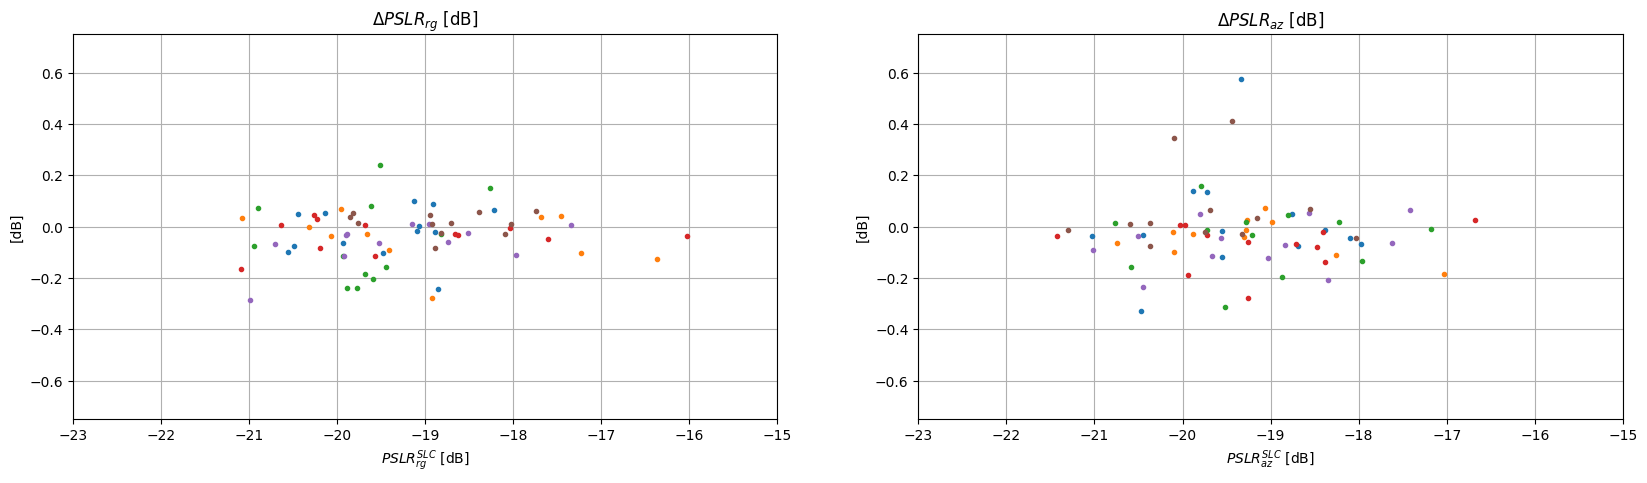

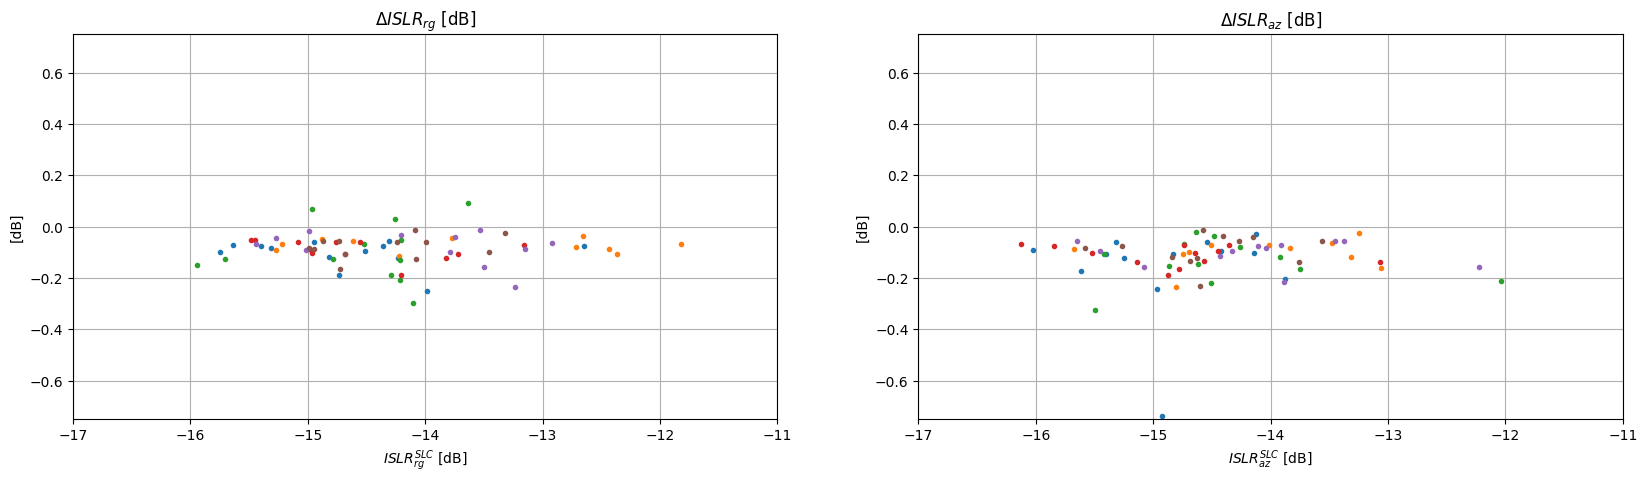

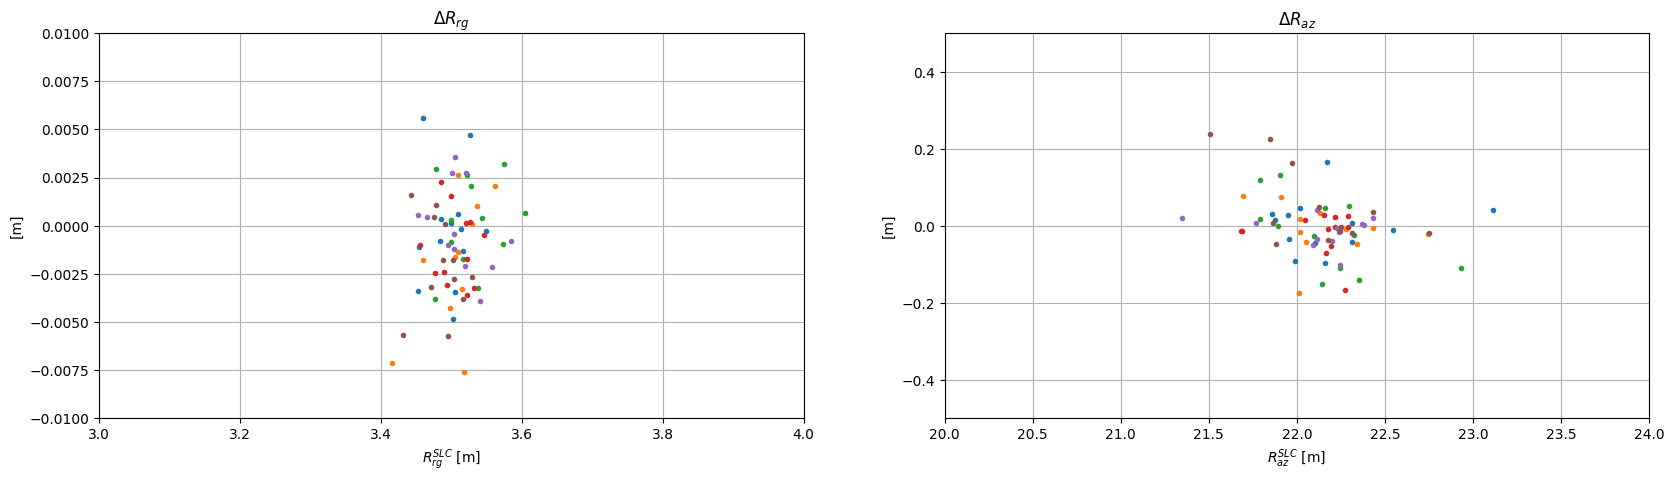

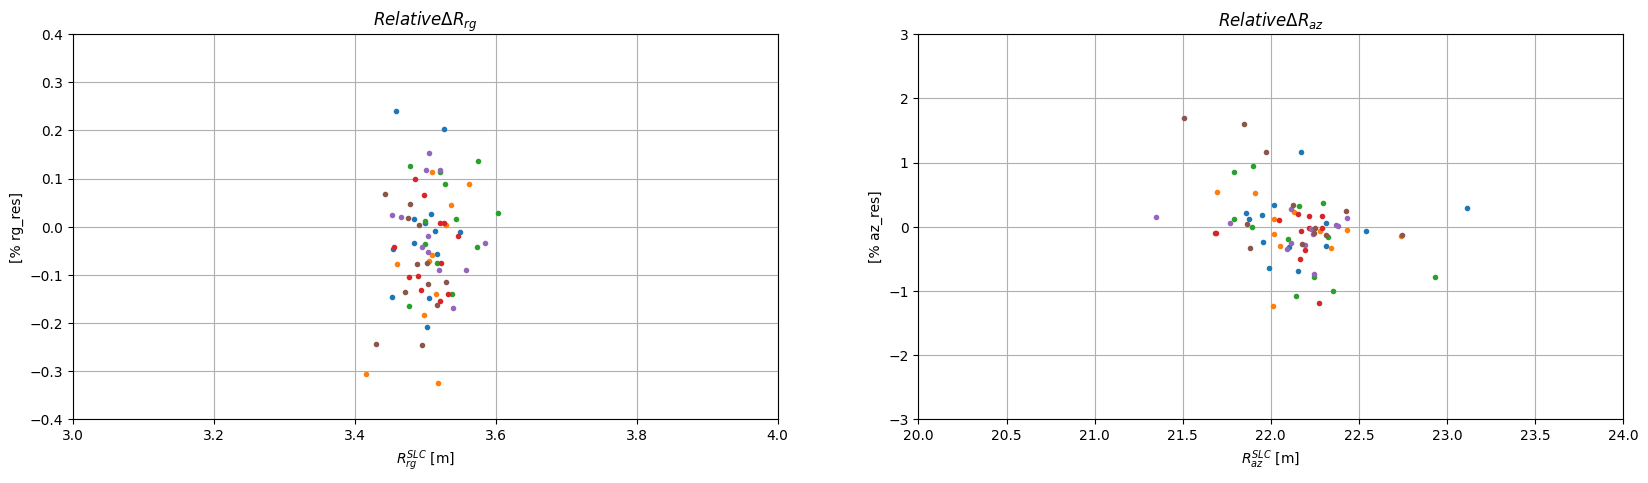

In [3]:
rcs_field, range_pslr_field, azimuth_pslr_field = (
    "rcs_[dB]",
    "range_pslr_[dB]",
    "azimuth_pslr_[dB]",
)
range_islr_field, azimuth_islr_field = "range_islr_[dB]", "azimuth_islr_[dB]"

fig1, axs1 = plt.subplots(1, 2, figsize=(20, 5))
fig2, axs2 = plt.subplots(1, 2, figsize=(20, 5))
fig3, axs3 = plt.subplots(1, 2, figsize=(20, 5))
fig4, axs4 = plt.subplots(1, 2, figsize=(20, 5))

for k, c_res in coregistered_results_dict.items():
    print(f"Coregistered results for date {k}: {c_res.shape[0]} records")
    o_res = original_results_dict[k]
    m_res = master_results_dict[COREGISTRATION_REFERENCE_DATE]

    rg_pslr_diff = c_res[range_pslr_field] - o_res[range_pslr_field]
    az_pslr_diff = c_res[azimuth_pslr_field] - o_res[azimuth_pslr_field]
    rg_islr_diff = c_res[range_islr_field] - o_res[range_islr_field]
    az_islr_diff = c_res[azimuth_islr_field] - o_res[azimuth_islr_field]
    rg_res_diff = c_res["range_resolution_[m]"] - o_res["range_resolution_[m]"]
    az_res_diff = c_res["azimuth_resolution_[m]"] - o_res["azimuth_resolution_[m]"]

    axs1[0].set_title("$\Delta PSLR_{rg}$ [dB]")
    axs1[0].set_xlabel("$PSLR_{rg}^{SLC}$ [dB]")
    axs1[0].set_ylabel("[dB]")
    axs1[0].plot(o_res[range_pslr_field], rg_pslr_diff, ".")
    axs1[1].set_title("$\Delta PSLR_{az}$ [dB]")
    axs1[1].set_xlabel("$PSLR_{az}^{SLC}$ [dB]")
    axs1[1].set_ylabel("[dB]")
    axs1[1].plot(o_res[azimuth_pslr_field], az_pslr_diff, ".")

    axs2[0].set_title("$\Delta ISLR_{rg}$ [dB]")
    axs2[0].set_xlabel("$ISLR_{rg}^{SLC}$ [dB]")
    axs2[0].set_ylabel("[dB]")
    axs2[0].plot(o_res[range_islr_field], rg_islr_diff, ".")
    axs2[1].set_title("$\Delta ISLR_{az}$ [dB]")
    axs2[1].set_xlabel("$ISLR_{az}^{SLC}$ [dB]")
    axs2[1].set_ylabel("[dB]")
    axs2[1].plot(o_res[azimuth_islr_field], az_islr_diff, ".")

    axs3[0].set_title("$\Delta R_{rg}$")
    axs3[0].set_xlabel("$R_{rg}^{SLC}$ [m]")
    axs3[0].set_ylabel("[m]")
    axs3[0].plot(o_res["range_resolution_[m]"], rg_res_diff, ".")
    axs3[1].set_title("$\Delta R_{az}$")
    axs3[1].set_xlabel("$R_{az}^{SLC}$ [m]")
    axs3[1].set_ylabel("[m]")
    axs3[1].plot(o_res["azimuth_resolution_[m]"], az_res_diff, ".")

    rg_sp, az_sp = 2.329562114715323, 14.06811
    axs4[0].set_title("$Relative \Delta R_{rg}$")
    axs4[0].set_xlabel("$R_{rg}^{SLC}$ [m]")
    axs4[0].set_ylabel("[% rg_res]")
    axs4[0].plot(o_res["range_resolution_[m]"], rg_res_diff / rg_sp * 100, ".")
    axs4[1].set_title("$Relative \Delta R_{az}$")
    axs4[1].set_xlabel("$R_{az}^{SLC}$ [m]")
    axs4[1].set_ylabel("[% az_res]")
    axs4[1].plot(o_res["azimuth_resolution_[m]"], az_res_diff / az_sp * 100, ".")


for j in range(2):
    axs1[j].set_xlim(-23, -15)  # Set X-axis limits
    axs1[j].set_ylim(-0.75, +0.75)  # Set Y-axis limits
for j in range(2):
    axs2[j].set_xlim(-17, -11)  # Set X-axis limits
    axs2[j].set_ylim(-0.75, +0.75)  # Set Y-axis limits
axs3[1].set_xlim(20, 24)  # Set X-axis limits
axs3[0].set_xlim(3, 4)  # Set X-axis limits
axs3[1].set_ylim(-0.5, +0.5)  # Set Y-axis limits
axs3[0].set_ylim(-0.01, +0.01)  # Set Y-axis limits
axs4[1].set_xlim(20, 24)  # Set X-axis limits
axs4[0].set_xlim(3, 4)  # Set X-axis limits
axs4[1].set_ylim(-3, +3)  # Set Y-axis limits
axs4[0].set_ylim(-0.4, +0.4)  # Set Y-axis limits

for ax in axs1.flat:
    ax.grid(True)
for ax in axs2.flat:
    ax.grid(True)
for ax in axs3.flat:
    ax.grid(True)
for ax in axs4.flat:
    ax.grid(True)
plt.show()

## Co-registration Error

Coregistered results for date 2023-11-12: 13 records
Coregistered results for date 2023-11-24: 12 records
Coregistered results for date 2023-12-06: 14 records
Coregistered results for date 2023-12-30: 13 records
Coregistered results for date 2024-01-11: 13 records


(-1.2, 1.2)

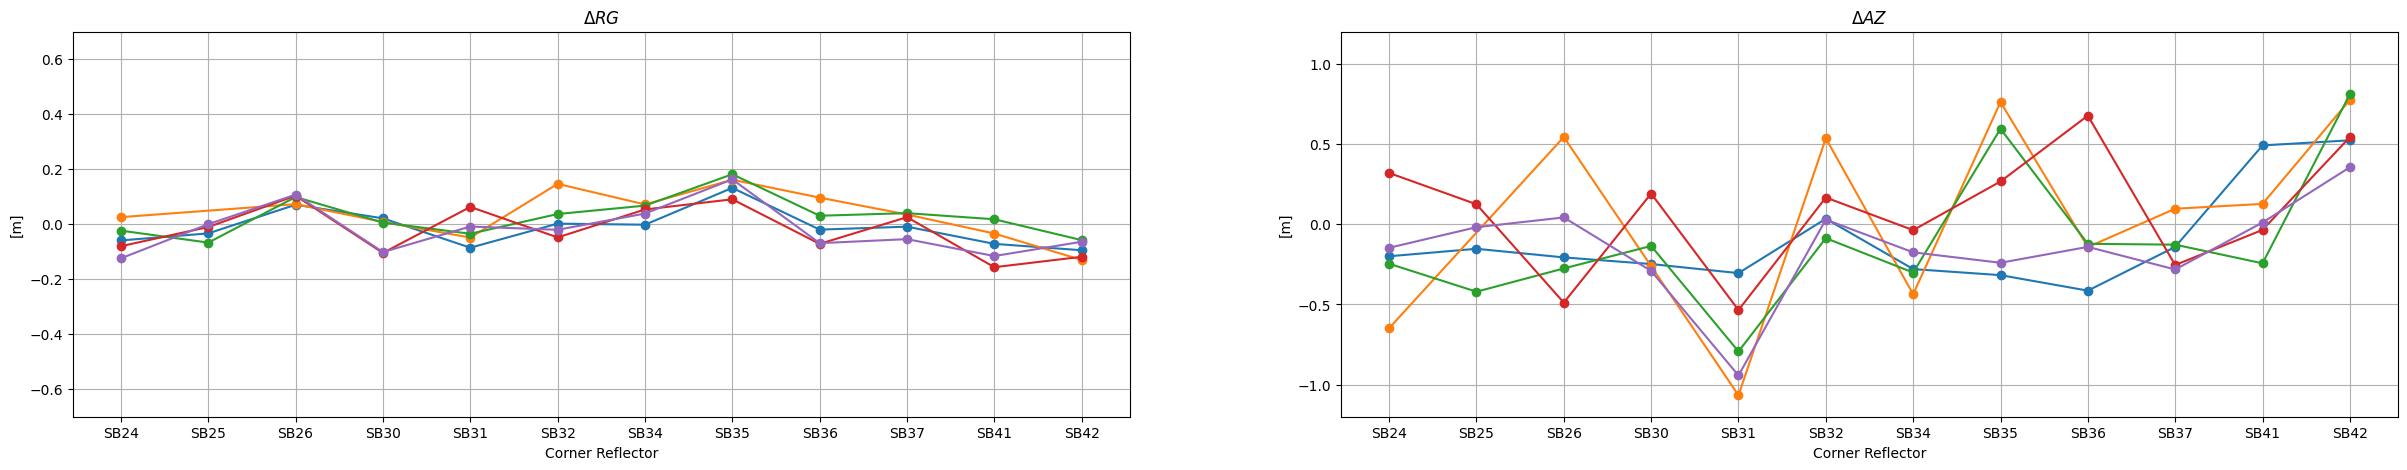

In [4]:
original_results_dict["2023-11-12"]

fig1, axs1 = plt.subplots(1, 2, figsize=(30, 5))

for k, c_res in coregistered_results_dict.items():
    if k == COREGISTRATION_REFERENCE_DATE:
        continue
    print(f"Coregistered results for date {k}: {c_res.shape[0]} records")

    o_res = original_results_dict[k]
    m_res = master_results_dict[COREGISTRATION_REFERENCE_DATE]
    target_names = []
    for i in np.unique(np.hstack((c_res.index.values, m_res.index.values))):
        try:
            target_names.append(c_res.loc[i]["target_name"].split("-")[0])
        except KeyError:
            target_names.append(m_res.loc[i]["target_name"].split("-")[0])
    target_names = np.array(target_names)
    rg_loc_diff = (
        c_res["slant_range_localization_error_[m]"]
        - m_res["slant_range_localization_error_[m]"]
    )
    az_loc_diff = (
        c_res["azimuth_localization_error_[m]"]
        - m_res["azimuth_localization_error_[m]"]
    )

    axs1[0].set_title("$\Delta RG$")
    axs1[0].set_xlabel("Corner Reflector")
    axs1[0].set_ylabel("[m]")

    (ii,) = np.where(np.isfinite(rg_loc_diff))
    axs1[0].plot(target_names[ii], rg_loc_diff.values[ii], marker="o", linestyle="-")
    axs1[1].set_title("$\Delta AZ$")
    axs1[1].set_xlabel("Corner Reflector")
    axs1[1].set_ylabel("[m]")
    axs1[1].plot(target_names[ii], az_loc_diff.values[ii], marker="o", linestyle="-")

for ax in axs1.flat:
    ax.grid(True)

axs1[0].set_ylim([-0.7, 0.7])
axs1[1].set_ylim([-1.2, 1.2])